# Comparativo de Algoritmos de Clustering

Agrupamiento Jerárquico, K-Means y DBSCAN.

## 1. Importación de librerias

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

## 2. Exploración y preprocesamiento de datos
Se revisan valores faltantes, outliers y se normalizan las variables numéricas.

In [2]:
# Cargar datos desde el archivo CSV
df = pd.read_csv('datos_clientes_clustering.csv')
print('Resumen estadístico:')
display(df.describe())
print('Valores faltantes:')
print(df.isnull().sum())

# Imputación de valores faltantes (si existieran)
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(imputer.fit_transform(df.drop('ID_Cliente', axis=1)), columns=df.columns[1:])
df_imputed['ID_Cliente'] = df['ID_Cliente']

# Eliminación de outliers con IQR
Q1 = df_imputed.quantile(0.25)
Q3 = df_imputed.quantile(0.75)
IQR = Q3 - Q1
df_clean = df_imputed[~((df_imputed < (Q1 - 1.5 * IQR)) | (df_imputed > (Q3 + 1.5 * IQR))).any(axis=1)]
print(f'Se eliminaron {len(df_imputed) - len(df_clean)} filas por outliers.')

# Normalización de variables numéricas
scaler = StandardScaler()
X = scaler.fit_transform(df_clean[['Edad','Ingresos_Anuales','Frecuencia_Mensual','Monto_Promedio_Compra','Visitas_Web','Dias_Desde_Ultima_Compra','Satisfaccion']])

Resumen estadístico:


,ID_Cliente,Edad,Ingresos_Anuales,Frecuencia_Mensual,Monto_Promedio_Compra,Visitas_Web,Dias_Desde_Ultima_Compra,Satisfaccion
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.00000
mean,500.500000,43.81900,50863.622304,7.889000,250.823304,14.864000,28.97000,2.87700
std,288.819436,14.99103,14823.245521,2.601432,98.281367,3.911112,16.83153,1.42334
min,1.000000,18.00000,6556.169327,1.000000,-64.141454,5.000000,1.00000,1.00000
25%,250.750000,31.00000,40822.467127,6.000000,185.025849,12.000000,14.75000,2.00000
50%,500.500000,44.00000,50807.530986,8.000000,250.374200,15.000000,28.00000,3.00000
75%,750.250000,56.00000,60282.053126,10.000000,317.592918,17.000000,43.00000,4.00000
max,1000.000000,69.00000,89485.730973,16.000000,604.406501,29.000000,59.00000,5.00000


Valores faltantes:
ID_Cliente                  0
Edad                        0
Ingresos_Anuales            0
Frecuencia_Mensual          0
Monto_Promedio_Compra       0
Visitas_Web                 0
Dias_Desde_Ultima_Compra    0
Satisfaccion                0
dtype: int64
Se eliminaron 32 filas por outliers.


## 3. Agrupamiento Jerárquico
El agrupamiento jerárquico construye una jerarquía de clusters. Hay dos tipos: aglomerativo (más común) y divisivo. El dendrograma es una herramienta visual que muestra cómo se agrupan los datos.

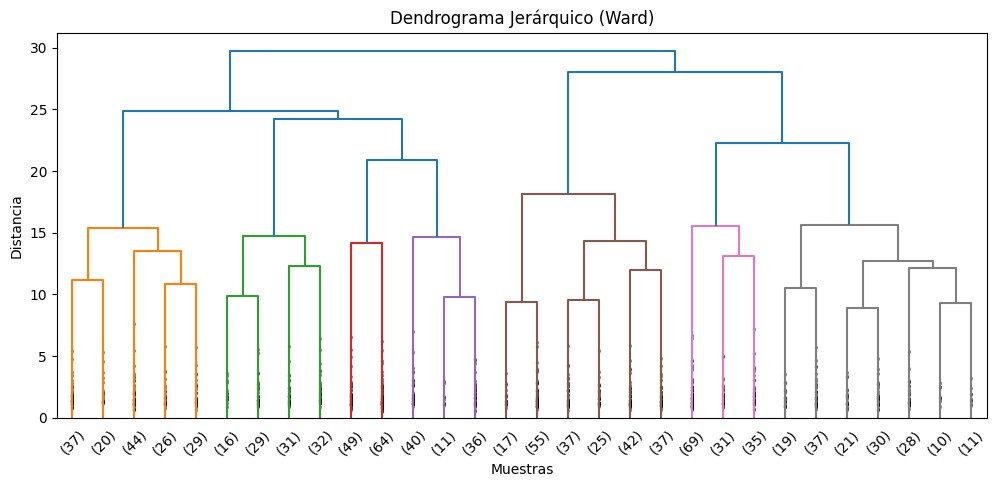

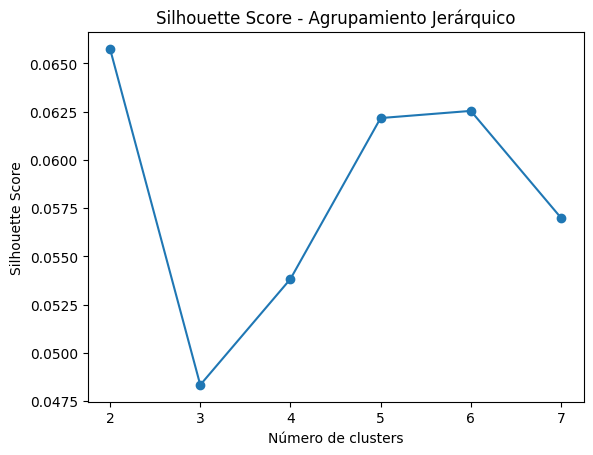

Cantidad óptima de clusters: 2


C:\Users\adria\AppData\Local\Temp\ipykernel_32068\2437125042.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['cluster_agglo'] = labels_agglo


In [3]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

linked = linkage(X, method='ward')
plt.figure(figsize=(12,5))
dendrogram(linked, truncate_mode='lastp', p=30, leaf_rotation=45, leaf_font_size=10, show_contracted=True)
plt.title('Dendrograma Jerárquico (Ward)')
plt.xlabel('Muestras')
plt.ylabel('Distancia')
plt.show()

# Elección de cantidad de clusters (por dendrograma o Silhouette)
from sklearn.metrics import silhouette_score
sil_scores = []
K = range(2, 8)
for k in K:
    agglo = AgglomerativeClustering(n_clusters=k)
    labels = agglo.fit_predict(X)
    sil_scores.append(silhouette_score(X, labels))
plt.plot(K, sil_scores, marker='o')
plt.xlabel('Número de clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score - Agrupamiento Jerárquico')
plt.show()
optimal_k = K[np.argmax(sil_scores)]
print(f'Cantidad óptima de clusters: {optimal_k}')
agglo = AgglomerativeClustering(n_clusters=optimal_k)
labels_agglo = agglo.fit_predict(X)
df_clean['cluster_agglo'] = labels_agglo

## 4. Algoritmo K-Means
K-Means agrupa los datos en k clusters minimizando la distancia a los centroides. Se elige k usando el método del codo y el coeficiente de silueta.

c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Wi

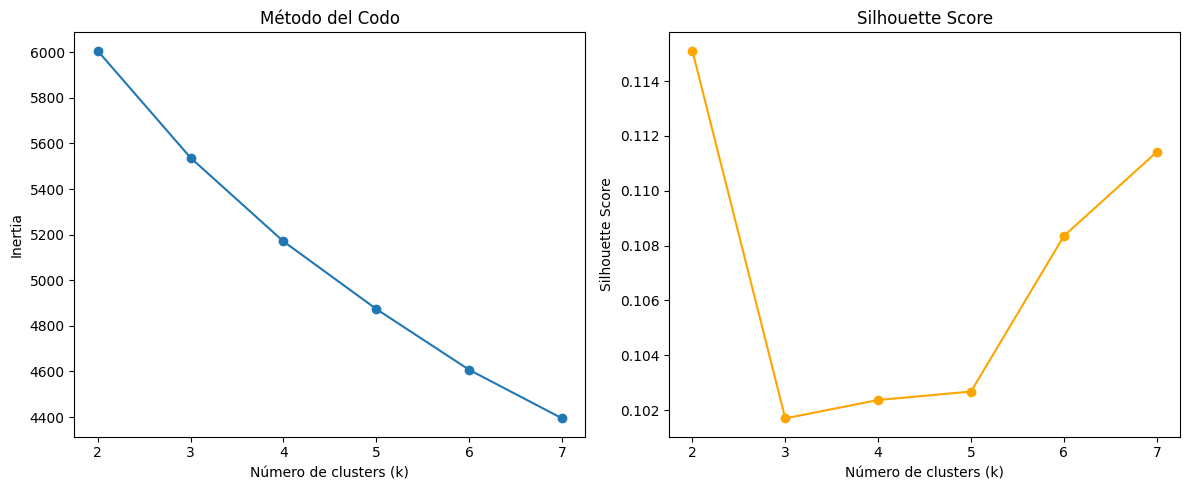

Cantidad óptima de clusters: 2


c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\adria\AppData\Local\Temp\ipykernel_32068\648167361.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['cluster_kmeans'] = labels_kmeans


In [4]:
from sklearn.cluster import KMeans
inertia = []
sil_scores = []
K = range(2, 8)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X, labels))
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K, inertia, marker='o')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inertia')
plt.title('Método del Codo')
plt.subplot(1,2,2)
plt.plot(K, sil_scores, marker='o', color='orange')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()
optimal_k = K[np.argmax(sil_scores)]
print(f'Cantidad óptima de clusters: {optimal_k}')
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X)
df_clean['cluster_kmeans'] = labels_kmeans

## 5. Algoritmo DBSCAN
DBSCAN agrupa puntos densos y detecta ruido. Sus parámetros principales son eps (radio de vecindad) y min_samples (mínimo de puntos por grupo).

C:\Users\adria\AppData\Local\Temp\ipykernel_32068\918668351.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['cluster_dbscan'] = labels_dbscan


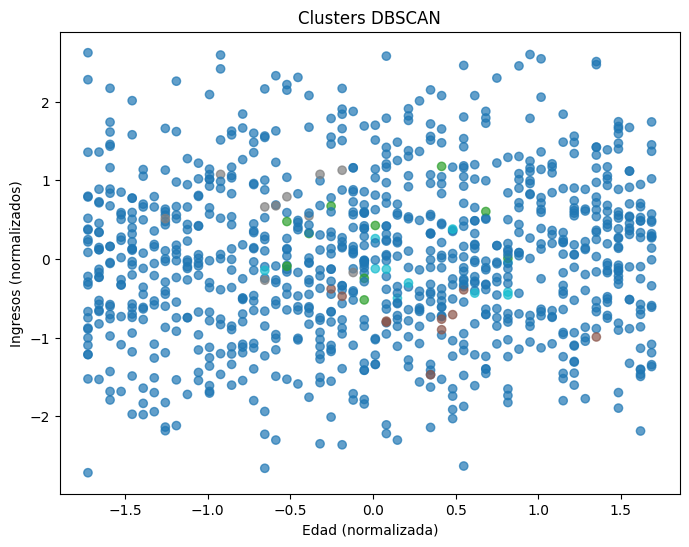

Etiquetas DBSCAN: -1 indica ruido/anomalía


In [5]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=1.2, min_samples=10)
labels_dbscan = dbscan.fit_predict(X)
df_clean['cluster_dbscan'] = labels_dbscan
plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1], c=labels_dbscan, cmap='tab10', alpha=0.7)
plt.xlabel('Edad (normalizada)')
plt.ylabel('Ingresos (normalizados)')
plt.title('Clusters DBSCAN')
plt.show()
print('Etiquetas DBSCAN: -1 indica ruido/anomalía')

## 6. Visualización comparativa de clusters
Se visualizan los clusters obtenidos por cada método en las dos primeras variables normalizadas.

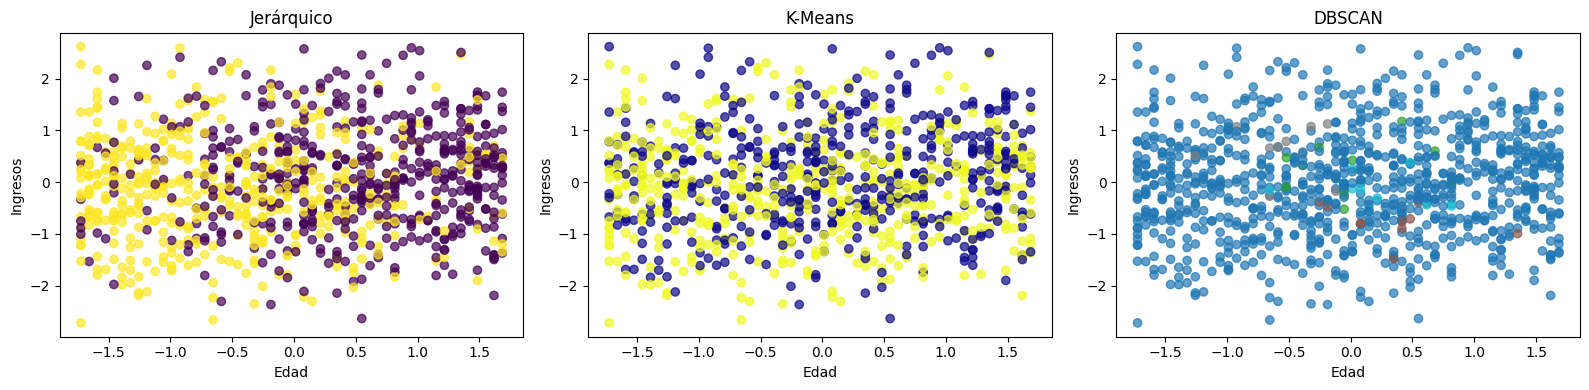

In [6]:
plt.figure(figsize=(16,4))
plt.subplot(1,3,1)
plt.scatter(X[:,0], X[:,1], c=df_clean['cluster_agglo'], cmap='viridis', alpha=0.7)
plt.title('Jerárquico')
plt.xlabel('Edad')
plt.ylabel('Ingresos')
plt.subplot(1,3,2)
plt.scatter(X[:,0], X[:,1], c=df_clean['cluster_kmeans'], cmap='plasma', alpha=0.7)
plt.title('K-Means')
plt.xlabel('Edad')
plt.ylabel('Ingresos')
plt.subplot(1,3,3)
plt.scatter(X[:,0], X[:,1], c=df_clean['cluster_dbscan'], cmap='tab10', alpha=0.7)
plt.title('DBSCAN')
plt.xlabel('Edad')
plt.ylabel('Ingresos')
plt.tight_layout()
plt.show()

## 7. Análisis comparativo de resultados
### Diferencias entre métodos
- El agrupamiento jerárquico permite visualizar la estructura de los datos y elegir el número de clusters con el dendrograma.
- K-Means es eficiente y fácil de interpretar, pero requiere especificar k y asume clusters esféricos.
- DBSCAN detecta grupos de forma arbitraria y ruido, útil para datos con formas complejas o presencia de anomalías.

### Interpretación de patrones
- Los clusters de K-Means y jerárquico suelen ser similares si los datos son bien separados.
- DBSCAN puede identificar grupos pequeños y puntos atípicos (-1).
- En este ejemplo, los clusters reflejan diferentes perfiles de clientes según edad, ingresos y hábitos de compra.

### Aplicabilidad
- K-Means: Recomendado para datos bien separados y sin mucho ruido.
- DBSCAN: Útil para detectar grupos de forma arbitraria y anomalías.
- Jerárquico: Ideal para explorar la estructura y decidir el número de clusters visualmente.

**Ventajas y desventajas de cada técnica se explican en los comentarios de cada sección.**

## Evaluación de variables por cluster para marketing, compras o ventas

In [7]:
# Evaluación de variables por cluster para marketing, compras o ventas
variables = ['Edad','Ingresos_Anuales','Frecuencia_Mensual','Monto_Promedio_Compra','Visitas_Web','Dias_Desde_Ultima_Compra','Satisfaccion']
print('--- Agrupamiento Jerárquico ---')
for c in sorted(df_clean['cluster_agglo'].unique()):
    grupo = df_clean[df_clean['cluster_agglo']==c]
    print(f'Cluster {c}:')
    print(grupo[variables].mean().round(2))
    print('-'*40)

print('--- K-Means ---')
for c in sorted(df_clean['cluster_kmeans'].unique()):
    grupo = df_clean[df_clean['cluster_kmeans']==c]
    print(f'Cluster {c}:')
    print(grupo[variables].mean().round(2))
    print('-'*40)

print('--- DBSCAN ---')
for c in sorted(df_clean['cluster_dbscan'].unique()):
    grupo = df_clean[df_clean['cluster_dbscan']==c]
    print(f'Cluster {c}:')
    print(grupo[variables].mean().round(2))
    print('-'*40)

--- Agrupamiento Jerárquico ---
Cluster 0:
Edad                           50.83
Ingresos_Anuales            52743.74
Frecuencia_Mensual              7.20
Monto_Promedio_Compra         254.94
Visitas_Web                    15.40
Dias_Desde_Ultima_Compra       33.47
Satisfaccion                    2.77
dtype: float64
----------------------------------------
Cluster 1:
Edad                           36.15
Ingresos_Anuales            49258.69
Frecuencia_Mensual              8.63
Monto_Promedio_Compra         247.80
Visitas_Web                    13.99
Dias_Desde_Ultima_Compra       23.74
Satisfaccion                    2.99
dtype: float64
----------------------------------------
--- K-Means ---
Cluster 0:
Edad                           45.10
Ingresos_Anuales            52965.58
Frecuencia_Mensual              7.80
Monto_Promedio_Compra         233.00
Visitas_Web                    14.61
Dias_Desde_Ultima_Compra       29.06
Satisfaccion                    1.66
dtype: float64
---------------